## 04 — Profile-reference correlation heatmaps across the Profile_7 sliding windows

### Aim
* Visualize, as profile × (patient, cell-type) correlation heatmaps, the same baseline and 6 window fits summarized numerically in `01_artifact_diagnosis.ipynb` Section 5, using the pseudobulk-reference heatmap style from that notebook's Section 2 and Figure 2 of `02_visualization.ipynb`.
* The question is the same as Section 5's: does the window matched to baseline Profile_7 show a visibly sharper (more cell-type-specific) correlation pattern as enrichment for Profile_7 increases, or does it stay diffuse regardless?

### Input
* Cached Stage 1 `cell_type_profiles.tsv` for the baseline n=150/k=9 fit (`data/deconvolution/xdec/stage1_with_refs_k9_n150`) and the 6 overlapping 40-sample windows (`data/deconvolution/xdec/sliding_window_profile7/stage1_rank*`), all produced by `01_artifact_diagnosis.ipynb`
* Peng et al. single-cell reference (`refs.tsv`, `ref_metadata.tsv`) and the shared Stage-0 probe list (`stage0/selected_probes.txt`)

### Output
* 7 profile × (patient, cell-type) Spearman-correlation clustermaps (baseline + 6 windows, low→high Profile_7 enrichment), each with its matched-to-baseline-Profile_7 row label highlighted, saved to `paper_duplication/figures/`

### Steps
* Rebuild the patient × cell-type pseudobulk reference means and cell-type color legend (same layout as Figure 2)
* For each fit, correlate its 9 estimated profiles against the pseudobulk reference over the shared Stage-0 probes
* Re-identify each window's best match to baseline Profile_7 (same Spearman-matching method as Section 5) to highlight it on the heatmap
* Render one fixed-scale (0-1) clustermap per fit, ordered by window enrichment

### Result
* Baseline Profile_7's row is dark blue (r≈0.4-0.8) across essentially every one of the 270 patient×cell-type reference columns — a visibly flat, non-specific row, not a spike over one cell-type block.
* Every window's matched profile (Profile_8 in 4/6 windows, Profile_1 and Profile_6 in the other two) reproduces that same flat, broadly-dark row — including the lowest-enrichment window (0.7% mean Profile_7 proportion) and the highest (17.7%), which look visually indistinguishable in breadth.
* No panel shows the matched profile's row concentrating onto one cell-type's column block as enrichment increases.

### Conclusion
* The heatmaps corroborate Section 5's numeric result visually: the ambiguous profile's broad, non-specific reference correlation is present at every enrichment level tested, not something that sharpens as the window is enriched for it. This remains consistent with, not proof of, an NNLS estimation artifact rather than a real minority compartment.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Find progress/ from either the notebook directory or progress/ itself.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)
XDEC_DIR = "data/deconvolution/xdec"
WINDOWS_DIR = os.path.join(XDEC_DIR, "sliding_window_profile7")
BASELINE_STAGE1_DIR = os.path.join(XDEC_DIR, "stage1_with_refs_k9_n150")
CORR_THRESHOLD = 0.3

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)


def read_genes(path):
    genes = Path(path).read_text().splitlines()
    return list(dict.fromkeys(g.strip() for g in genes if g.strip()))

### Pseudobulk reference

Average reference single cells within each (patient, cell type), exactly as in Figure 2 of `02_visualization.ipynb` and Section 2 of `01_artifact_diagnosis.ipynb`. Columns are ordered by biological compartment; this ordering and the cell-type color legend are reused unchanged across all 7 panels below.

In [2]:
refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)
probe_list = read_genes(os.path.join(XDEC_DIR, "stage0", "selected_probes.txt"))

if not refs.index.is_unique or not refs.columns.is_unique or not ref_meta.index.is_unique:
    raise ValueError("Duplicate reference or metadata labels")
ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]
if ref_cell_types.isna().any():
    raise ValueError("Missing cell types in reference metadata")

cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
if set(cell_type_order) != set(ref_cell_types.unique()):
    raise ValueError("Cell-type order must cover the reference metadata")
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))

patients = pd.Series(refs.columns, index=refs.columns).str.split("_").str[0]
if patients.eq("").any() or not refs.columns.str.contains("_").all():
    raise ValueError("Expected patient-prefixed reference cell IDs")
group_key = patients + " | " + ref_cell_types.astype(str)
reference_means = refs.T.groupby(group_key, sort=True).mean().T
pb_cell_types = pd.Series({c: c.split(" | ", 1)[1] for c in reference_means.columns})
pb_order = pb_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
reference_means = reference_means.loc[:, pb_order]
profile_order = [f"Profile_{i}" for i in range(1, 10)]
print(f"Pseudobulk reference: {reference_means.shape[0]} genes × {reference_means.shape[1]} (patient, cell-type) columns")

Pseudobulk reference: 17004 genes × 270 (patient, cell-type) columns


### Fit discovery and matched-profile identification

Discover the cached baseline fit and the 6 cached window fits from `01_artifact_diagnosis.ipynb` Section 5. For each window, recompute its mean baseline-Profile_7 enrichment and its best-matching profile (by Spearman correlation of `cell_type_profiles.tsv` to baseline Profile_7 over shared Stage-0 probes) — the same method Section 5 used, so the two notebooks agree without one importing the other.

In [3]:
window_stage1_dirs = sorted(
    Path(WINDOWS_DIR).glob("stage1_rank*"),
    key=lambda p: int(p.name.split("rank")[1].split("_")[0]),
)
if len(window_stage1_dirs) != 6:
    raise FileNotFoundError(
        f"Expected 6 cached sliding-window Stage 1 fits in {WINDOWS_DIR}; found {len(window_stage1_dirs)}. "
        "Run 01_artifact_diagnosis.ipynb Section 5 first."
    )

baseline_proportions = pd.read_csv(os.path.join(BASELINE_STAGE1_DIR, "proportions.tsv"), sep="\t", index_col=0)
baseline_profiles = pd.read_csv(os.path.join(BASELINE_STAGE1_DIR, "cell_type_profiles.tsv"), sep="\t", index_col=0)
baseline_profile7 = baseline_profiles["Profile_7"]


def match_to_baseline_profile7(window_profiles, genes):
    common = [g for g in genes if g in baseline_profile7.index and g in window_profiles.index]
    if len(common) < 10:
        raise ValueError("Too few shared probes to match a window profile to baseline Profile_7")
    corrs = window_profiles.loc[common].corrwith(baseline_profile7.loc[common], method="spearman")
    if corrs.isna().all():
        raise ValueError("All window-profile correlations to baseline Profile_7 are undefined")
    return corrs.idxmax(), float(corrs.max())


fits = [{"label": "baseline (n=150)", "tag": "baseline", "stage1_dir": BASELINE_STAGE1_DIR,
         "matched_profile": "Profile_7", "match_r": 1.0, "mean_profile7_proportion": None}]

for s1_dir in window_stage1_dirs:
    tag = s1_dir.name.removeprefix("stage1_")
    w_props = pd.read_csv(s1_dir / "proportions.tsv", sep="\t", index_col=0)
    w_profiles = pd.read_csv(s1_dir / "cell_type_profiles.tsv", sep="\t", index_col=0)
    matched_profile, match_r = match_to_baseline_profile7(w_profiles, probe_list)
    fits.append({
        "label": tag,
        "tag": tag,
        "stage1_dir": str(s1_dir),
        "matched_profile": matched_profile,
        "match_r": match_r,
        "mean_profile7_proportion": float(baseline_proportions.loc[w_props.index, "Profile_7"].mean()),
    })

fits_df = pd.DataFrame(fits)
fits_df

,label,tag,stage1_dir,matched_profile,match_r,mean_profile7_proportion
0,baseline (n=150),baseline,data/deconvolution/xdec/stage1_with_refs_k9_n150,Profile_7,1.000000,NaN
1,rank000_040,rank000_040,data/deconvolution/xdec/sliding_window_profile...,Profile_8,0.430180,0.177138
2,rank022_062,rank022_062,data/deconvolution/xdec/sliding_window_profile...,Profile_6,0.508467,0.099692
3,rank044_084,rank044_084,data/deconvolution/xdec/sliding_window_profile...,Profile_6,0.373235,0.064029
4,rank066_106,rank066_106,data/deconvolution/xdec/sliding_window_profile...,Profile_8,0.405592,0.039690
5,rank088_128,rank088_128,data/deconvolution/xdec/sliding_window_profile...,Profile_1,0.298509,0.020956
6,rank110_150,rank110_150,data/deconvolution/xdec/sliding_window_profile...,Profile_8,0.348020,0.007233


### Correlation heatmaps

One clustermap per fit (baseline, then the 6 windows in increasing Profile_7 enrichment), all on the same 0-1 color scale and cell-type ordering. Rows are `Profile_1`-`Profile_9`, not clustered, so a profile's row position is comparable across panels; the y-tick label of the profile matched to baseline Profile_7 is bolded and colored red.

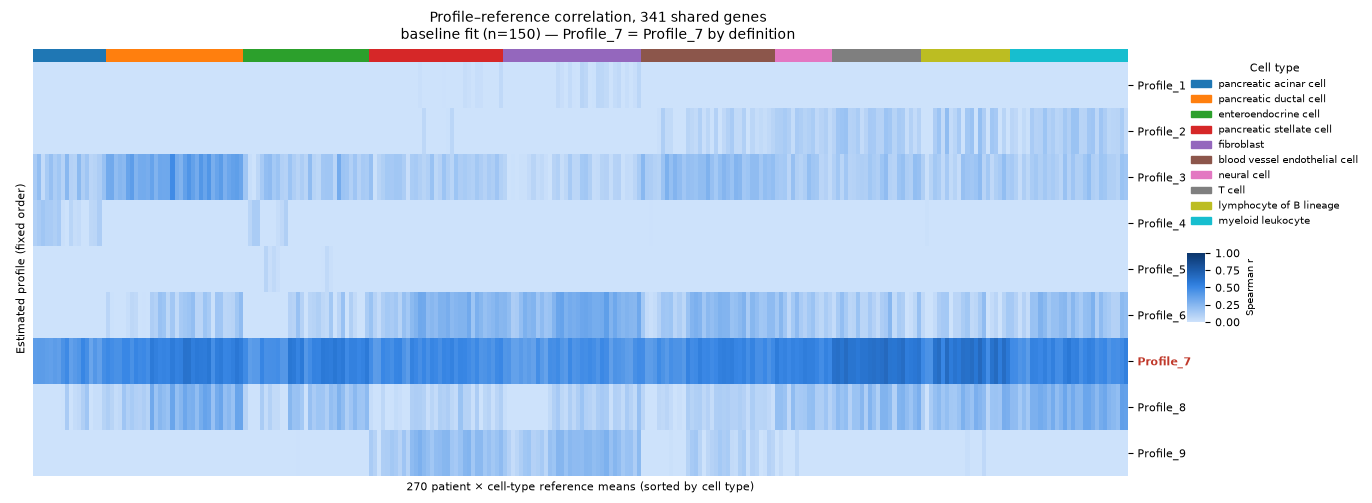

baseline (n=150): saved paper_duplication/figures/fig_sliding_window_baseline_profile_reference_correlation.png


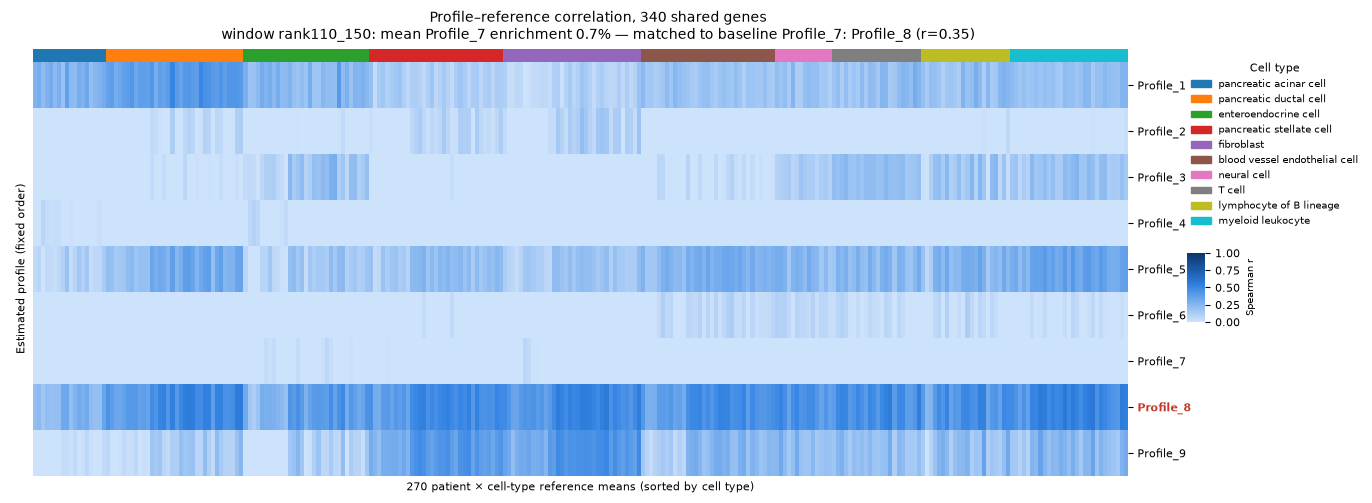

rank110_150: saved paper_duplication/figures/fig_sliding_window_rank110_150_profile_reference_correlation.png


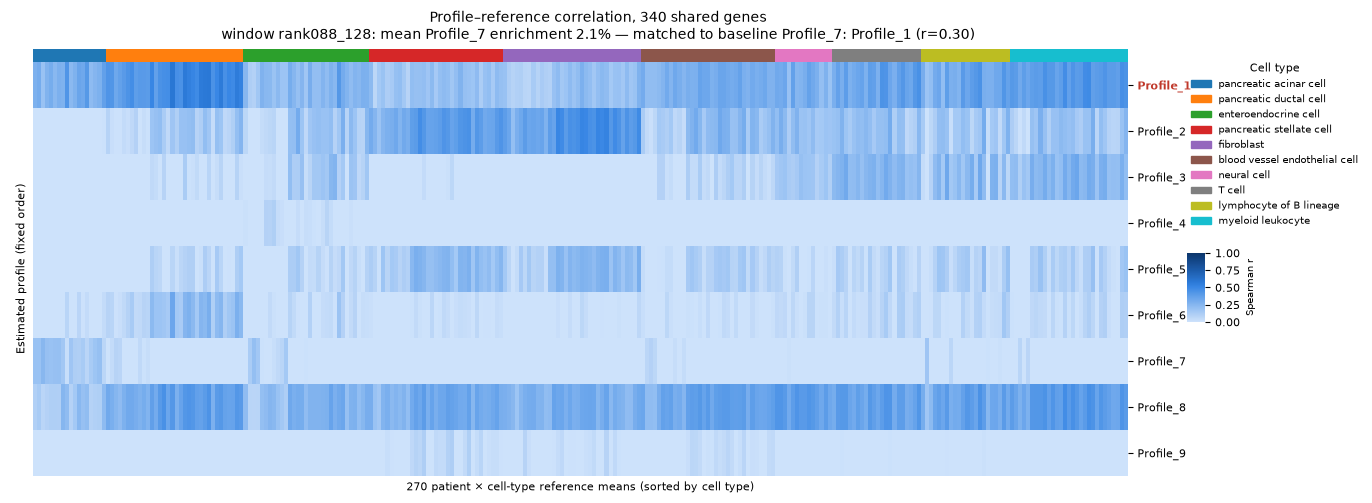

rank088_128: saved paper_duplication/figures/fig_sliding_window_rank088_128_profile_reference_correlation.png


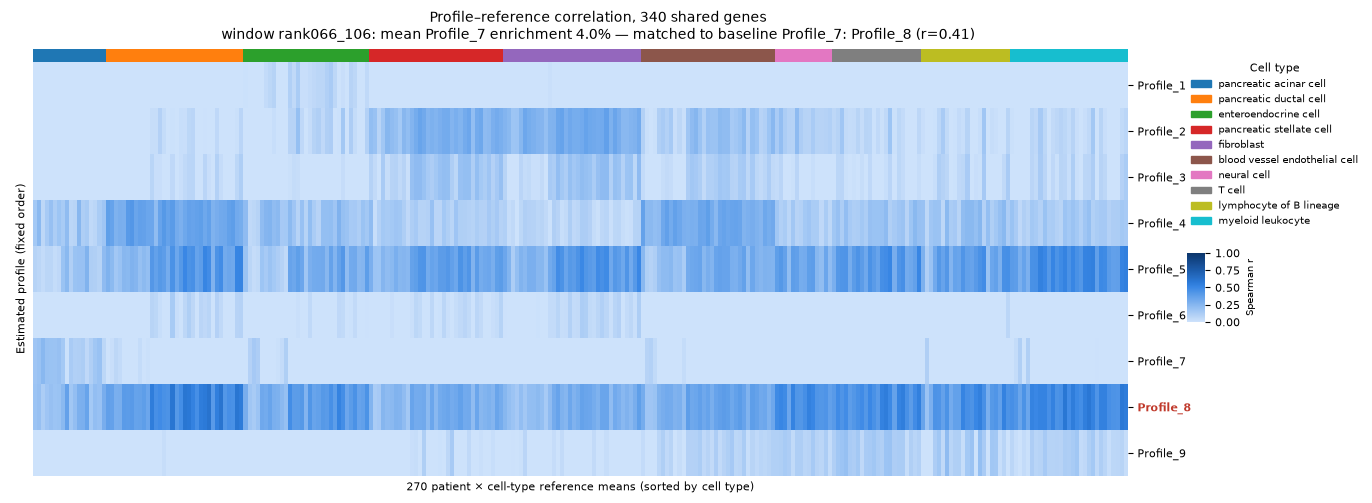

rank066_106: saved paper_duplication/figures/fig_sliding_window_rank066_106_profile_reference_correlation.png


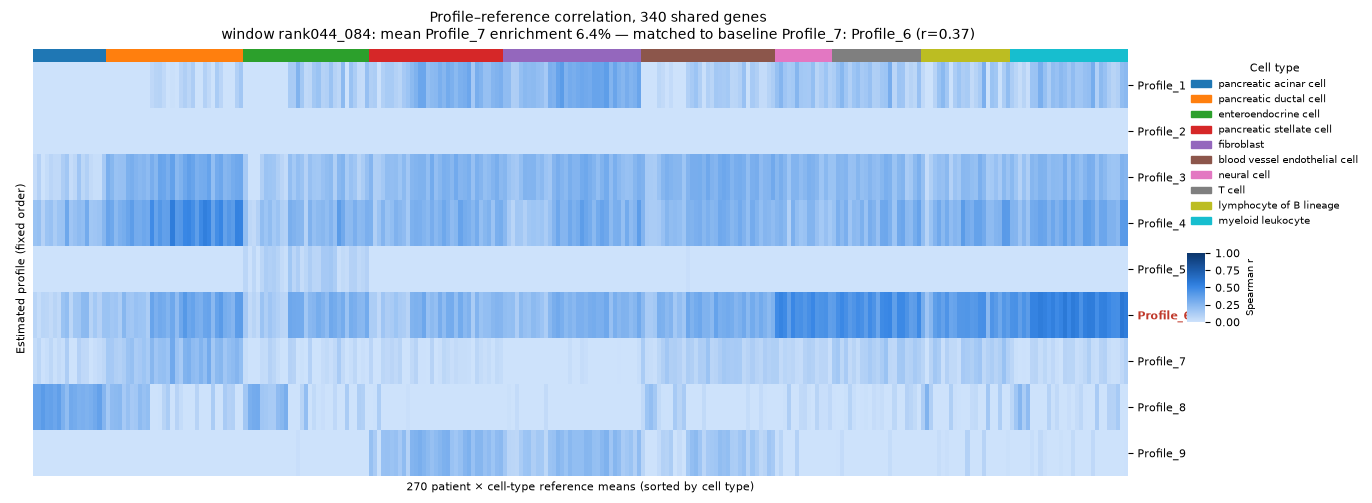

rank044_084: saved paper_duplication/figures/fig_sliding_window_rank044_084_profile_reference_correlation.png


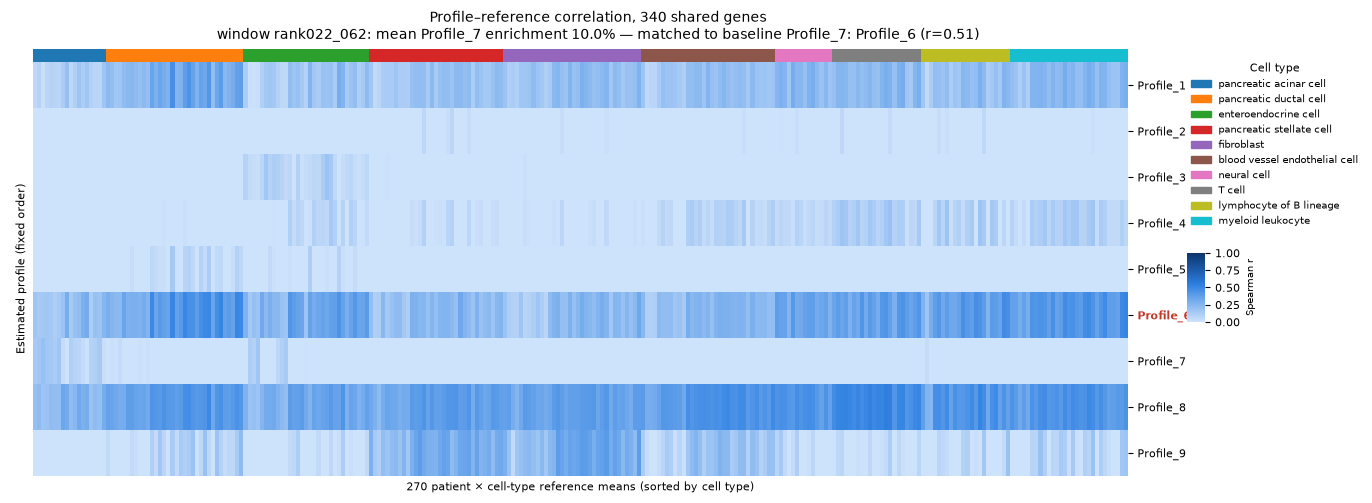

rank022_062: saved paper_duplication/figures/fig_sliding_window_rank022_062_profile_reference_correlation.png


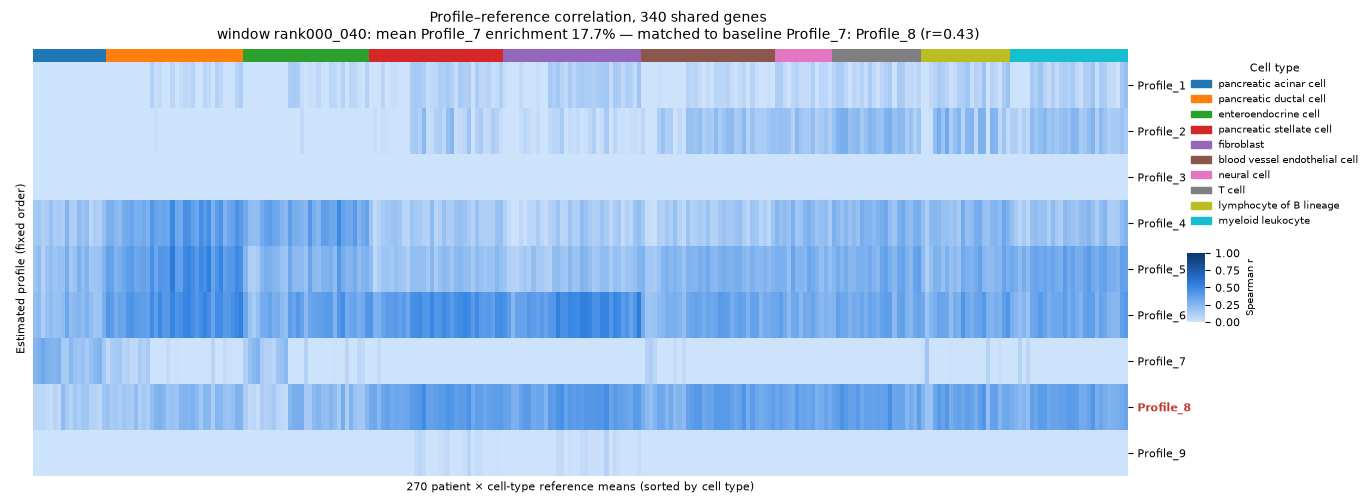

rank000_040: saved paper_duplication/figures/fig_sliding_window_rank000_040_profile_reference_correlation.png


In [4]:
heatmap_dir = Path("paper_duplication/figures")
heatmap_dir.mkdir(parents=True, exist_ok=True)
vmin, vmax = 0.0, 1.0

ordered_fits = [fits[0]] + sorted(fits[1:], key=lambda f: f["mean_profile7_proportion"])
correlation_panels = {}

for fit in ordered_fits:
    profiles = pd.read_csv(Path(fit["stage1_dir"]) / "cell_type_profiles.tsv", sep="\t", index_col=0)
    genes = [g for g in probe_list if g in refs.index and g in profiles.index]
    if len(genes) < 3:
        raise ValueError(f"{fit['label']}: insufficient shared genes")
    combined = pd.concat([reference_means.loc[genes], profiles.loc[genes, profile_order]], axis=1)
    correlations = combined.corr(method="spearman").loc[profile_order, pb_order]
    if not np.isfinite(correlations.to_numpy()).all():
        raise ValueError(f"{fit['label']}: undefined correlations; check for constant expression vectors")
    correlation_panels[fit["tag"]] = correlations

    grid = sns.clustermap(
        correlations, row_cluster=False, col_cluster=False,
        col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
        cmap=seq_blue, vmin=vmin, vmax=vmax,
        xticklabels=False, yticklabels=True, figsize=(12, 4.6),
        cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.02, 0.02),
    )
    grid.ax_heatmap.set_xlabel(f"{len(pb_order)} patient × cell-type reference means (sorted by cell type)")
    grid.ax_heatmap.set_ylabel("Estimated profile (fixed order)")
    grid.ax_heatmap.yaxis.set_label_position("left")
    grid.ax_heatmap.tick_params(axis="y", rotation=0)
    for lbl in grid.ax_heatmap.get_yticklabels():
        if lbl.get_text() == fit["matched_profile"]:
            lbl.set_weight("bold")
            lbl.set_color("#c0392b")

    handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
    legend = grid.ax_heatmap.legend(
        handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
        loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
    )

    if fit["mean_profile7_proportion"] is None:
        subtitle = f"baseline fit (n=150) — {fit['matched_profile']} = Profile_7 by definition"
    else:
        subtitle = (f"window {fit['tag']}: mean Profile_7 enrichment "
                    f"{fit['mean_profile7_proportion']:.1%} — matched to baseline Profile_7: "
                    f"{fit['matched_profile']} (r={fit['match_r']:.2f})")
    grid.fig.suptitle(f"Profile–reference correlation, {len(genes)} shared genes\n{subtitle}", y=1.04, fontsize=10)

    grid.fig.canvas.draw()
    bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
    grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
    grid.cax.yaxis.label.set_fontsize(7)

    output = heatmap_dir / f"fig_sliding_window_{fit['tag']}_profile_reference_correlation.png"
    grid.savefig(output, dpi=200, bbox_inches="tight")
    correlations.to_csv(output.with_suffix(".tsv"), sep="\t")
    plt.show()
    plt.close(grid.fig)
    print(f"{fit['label']}: saved {output}")